In [1]:
import sys
sys.path.insert(0, "/Users/ashwanishah/Desktop/AQI/MODEL/Utility_fun")
import aqi_utils as U


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 768, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
 # ===== ITO – Part A: Setup, load and tidy =====
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import aqi_utils as U

STATION  = "Rajesthan_jodhpur"
DATA_DIR = "/Users/ashwanishah/Desktop/AQI/DATASETS/Jodhpur"                 
LAT, LON =  26.3535, 73.0331          
FIG = "figures_Patia"
os.makedirs(FIG, exist_ok=True)

# 1. load all files
raw = U.load_cpcb(DATA_DIR)

# 2. tidy: drop empty columns, remove duplicate hours, fill in missing hours
n_before = len(raw)
raw = U.tidy(raw)
print("\nShape:", raw.shape, "| from", raw.index.min(), "to", raw.index.max())
print("Hours in files:", n_before, "| full hourly timeline:", len(raw))

# 3. missing % per column
print("\nMissing % per column:")
print((raw.isna().mean() * 100).round(1).sort_values())

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/opt/anaconda3/lib/python3.12/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


files: ['Jodhpur-2023-mandoor.xlsx', 'Jodhpur-2024-mandoor.xlsx', 'Jodhpur-2025-mandoor.xlsx', 'Jodhpur-2026-mandoor(SEPT).xlsx']

Shape: (32832, 15) | from 2023-01-01 00:00:00 to 2026-09-29 23:00:00
Hours in files: 32783 | full hourly timeline: 32832

Missing % per column:
RF         10.2
SR         10.4
BENZENE    10.5
RH         10.5
AT         10.5
WD         10.6
WS         10.6
NO         10.7
NO2        10.7
CO         10.9
TOLUENE    10.9
SO2        11.0
PM10       11.2
PM2.5      11.4
NH3        11.9
dtype: float64


Removed by cleaning (hours) and missing % after:
         negative  flatline  stuck_0.1  missing_%_now
PM2.5           0         0          0           11.4
PM10            0         0          0           11.2
NO              0         6          0           10.7
NO2             0         0          2           10.7
NH3             0         0         16           12.0
SO2             0        42          0           11.2
CO              0       292          0           11.8
BENZENE         0      1840          0           16.1
TOLUENE         0       373          0           12.1


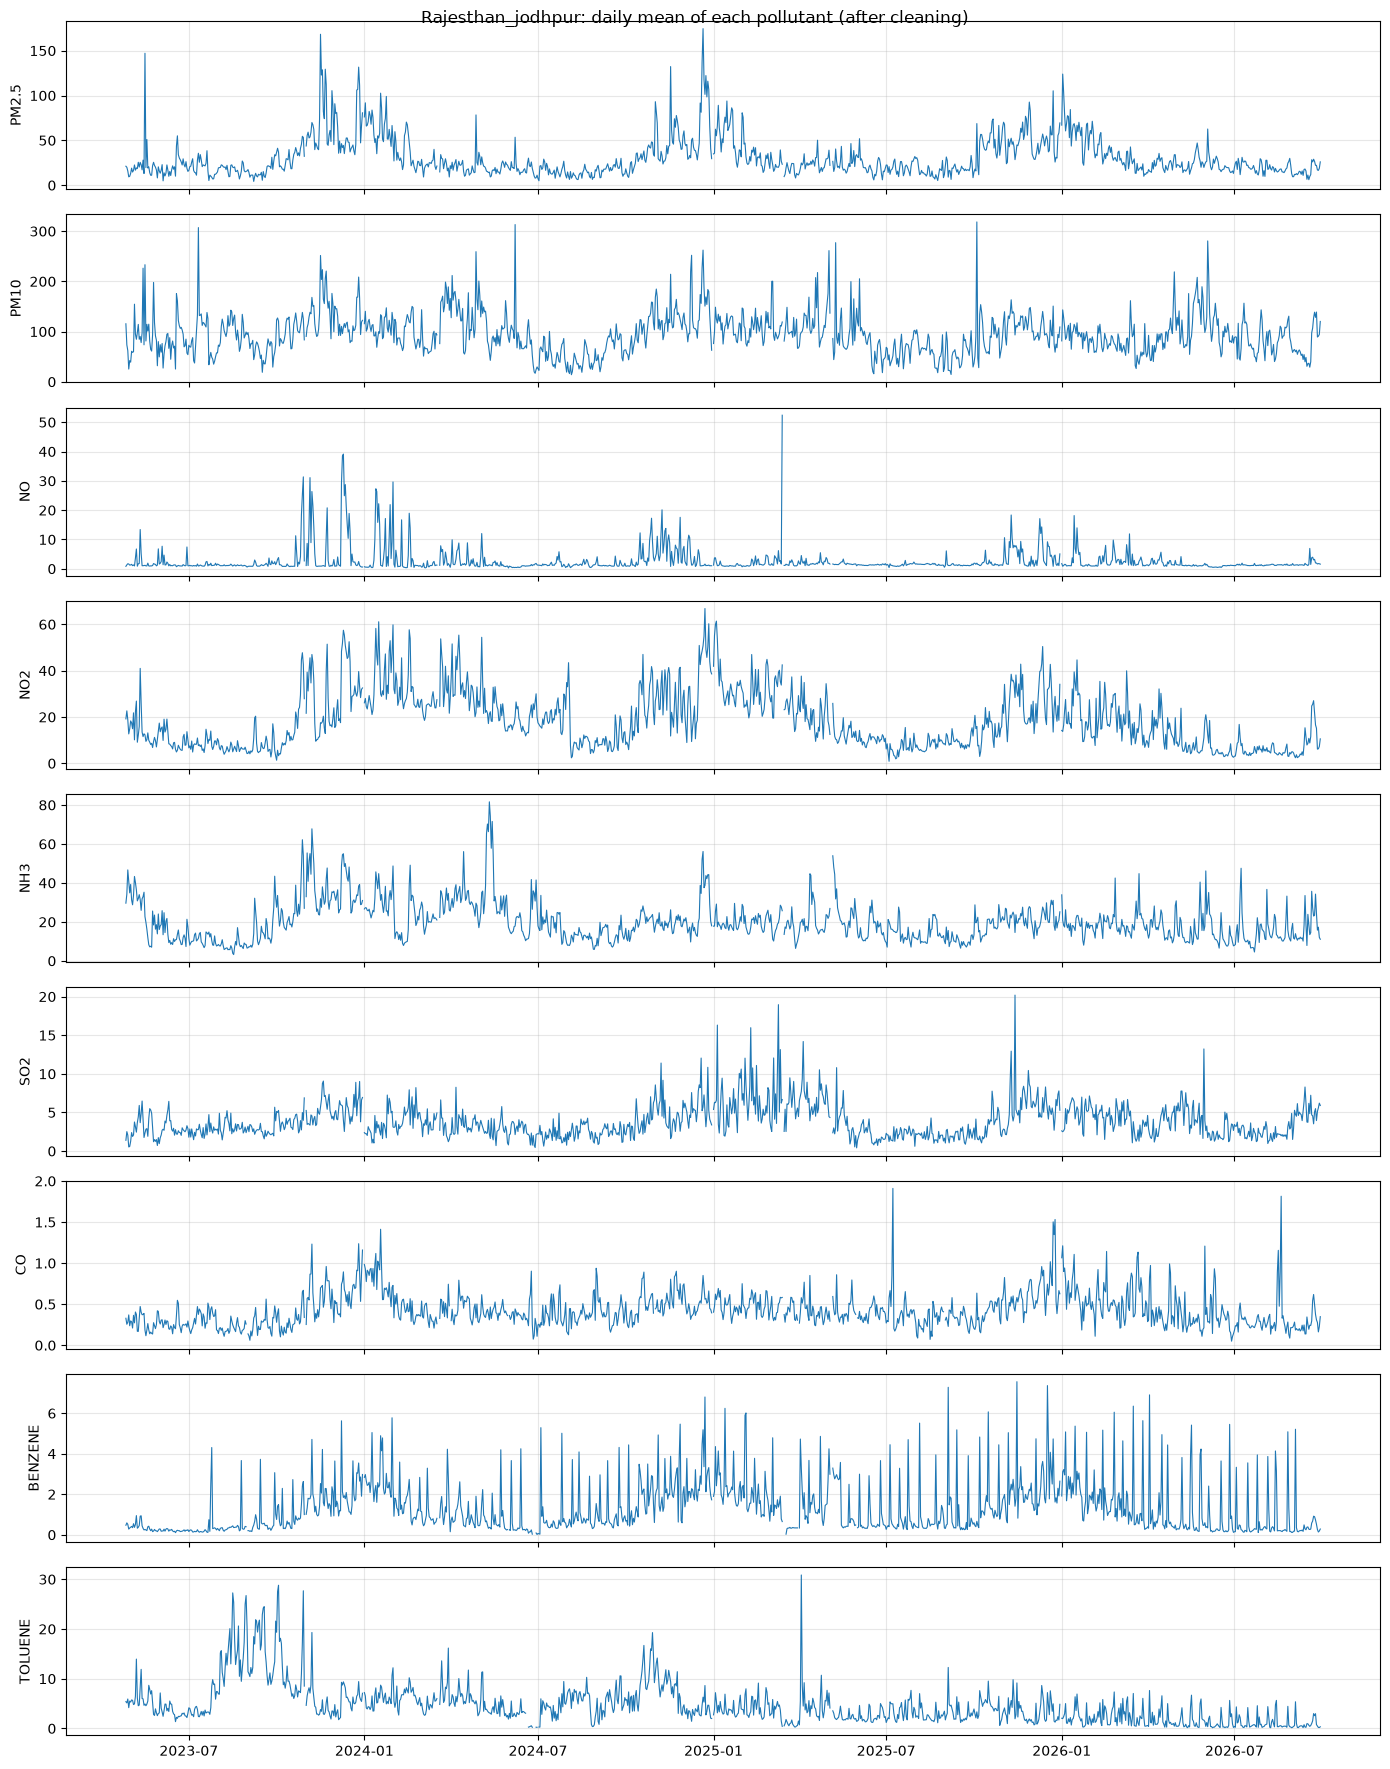

In [3]:
# ===== ITO – Part B: Clean and check the sensors =====
data, qc = U.clean_pollutants(raw)
print("Removed by cleaning (hours) and missing % after:")
print(qc)

# daily mean of each pollutant, 2023–2026
POLS = [p for p in U.ALL_POLS if p in data.columns]
daily = data[POLS].resample("D").mean()

fig, axes = plt.subplots(len(POLS), 1, figsize=(14, 2.0 * len(POLS)), sharex=True)
for ax, p in zip(axes, POLS):
    ax.plot(daily.index, daily[p], lw=0.8)
    ax.set_ylabel(p); ax.grid(alpha=0.3)
plt.suptitle(f"{STATION}: daily mean of each pollutant (after cleaning)")
plt.tight_layout(); plt.savefig(f"{FIG}/pollutants_daily.png", dpi=200); plt.show()

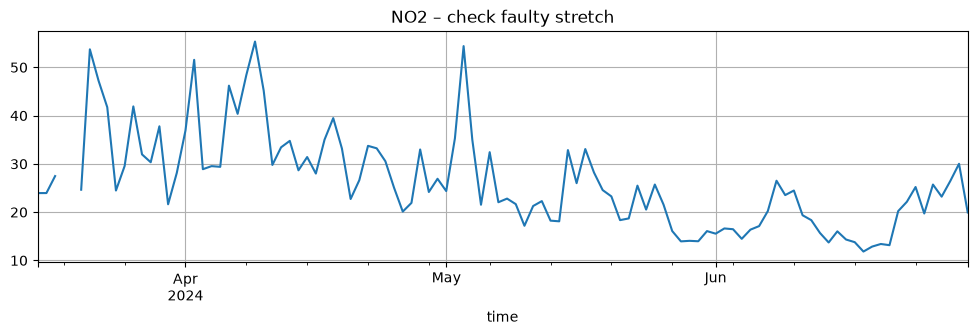

In [4]:
data["NO2"].resample("D").mean()["2024-03-15":"2024-06-30"].plot(figsize=(12, 3), grid=True, title="NO2 – check faulty stretch")
plt.show()

In [7]:
# ===== Jodhpur – Part B (decision) =====
DROPPED = {}                                   # all AQI pollutants look healthy
POLS_ITO = [p for p in U.AQI_POLS_ALL if p in data.columns]
print("Kept pollutants:", POLS_ITO)
print("Notes: data starts about May 2023; no ozone sensor at Mandor; "
      "Benzene shows regular calibration-like spikes (not used – not an AQI pollutant)")

Kept pollutants: ['PM2.5', 'PM10', 'NO2', 'SO2', 'NH3', 'CO']
Notes: data starts about May 2023; no ozone sensor at Mandor; Benzene shows regular calibration-like spikes (not used – not an AQI pollutant)


In [8]:
# ===== ITO – Part C: ERA5 weather =====
met = U.get_era5(LAT, LON,
                 str(data.index.min().date()), str(data.index.max().date()),
                 cache_file="era5_mandor.csv")
print("ERA5:", met.shape, met.index.min(), "to", met.index.max())
print("Missing %:", (met.isna().mean() * 100).round(1).to_dict())

data = U.use_era5(data, met)
print("\nColumns now:", list(data.columns))
print("Shape:", data.shape)

ERA5: (32832, 8) 2023-01-01 00:00:00 to 2026-09-29 23:00:00
Missing %: {'temperature_2m': 0.0, 'relative_humidity_2m': 0.0, 'shortwave_radiation': 0.0, 'precipitation': 0.0, 'wind_speed_10m': 0.0, 'wind_direction_10m': 0.0, 'surface_pressure': 0.0, 'cloud_cover': 0.0}

Columns now: ['PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'SO2', 'CO', 'BENZENE', 'TOLUENE', 'AT', 'RH', 'SR', 'RF', 'wind_speed_10m', 'WD', 'surface_pressure', 'cloud_cover']
Shape: (32832, 17)


In [9]:
# ===== ITO – Part D: Daily values, AQI, features =====
Y = U.make_daily_conc(data, POLS_ITO)                     # daily concentrations (targets)
X = U.build_features(data, Y, POLS_ITO)                   # inputs
pers = pd.DataFrame({p: X[f"{p}_lag1"] for p in POLS_ITO})  # persistence

aqi_true = U.compute_aqi(Y, POLS_ITO)
aqi_cat  = U.to_cat(aqi_true)
print("X:", X.shape, "| Y:", Y.shape)
print("Days with an AQI:", aqi_true.notna().sum(), "of", len(aqi_true))

# categories in each period
check = pd.DataFrame({s: aqi_cat[U.in_period(aqi_cat.index, s) & aqi_true.notna()].value_counts().reindex(U.CATS)
                      for s in U.SPLITS}).fillna(0).astype(int)
check.loc["total days"] = check.sum()
print("\nAQI categories per period:")
print(check)

# which pollutant decides the AQI
sub = pd.DataFrame({p: U.sub_index(Y[p], p) for p in POLS_ITO})
print("\nWhich pollutant decides the AQI (% of days):")
print((sub[aqi_true.notna()].idxmax(axis=1).value_counts(normalize=True) * 100).round(1))

X: (1368, 37) | Y: (1368, 6)
Days with an AQI: 1222 of 1368

AQI categories per period:
              train  val  test  test2
Good             73    1    42     22
Satisfactory    241   25   168    152
Moderate        183   53   134     89
Poor             12    8     6      2
Very Poor         6    4     0      1
Severe            0    0     0      0
total days      515   91   350    266

Which pollutant decides the AQI (% of days):
PM10     85.8
PM2.5    11.1
CO        2.4
NO2       0.7
Name: proportion, dtype: float64


In [10]:
# ===== ITO – Part E: Own model vs persistence (N2) =====
with open("/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved/final_params.json") as f:   # adjust path if needed
    FINAL_PARAMS = json.load(f)

FINAL_MODELS = ["Lasso", "ExtraTrees", "LightGBM", "HistGB"]
SEEDS = [0, 1, 2, 3, 4]
fit   = X.index <= "2024-12-31"
test  = U.in_period(X.index, "test")
test2 = U.in_period(X.index, "test2")

own_preds = {}
for name in FINAL_MODELS:
    own_preds[name] = [U.forecast(X[fit], Y[fit], X, POLS_ITO, name, {**FINAL_PARAMS[name], "random_state": s})
                       for s in SEEDS]
    print("done:", name)

for label, days in [("Test 2025", test), ("Test Jan–Sep 2026", test2)]:
    rows = [{"model": "Persistence", **U.scores(pers, days, Y, pers, POLS_ITO)}]
    for name in FINAL_MODELS:
        sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_ITO) for p in own_preds[name]])
        rows.append({"model": name, "days": sc.days.iloc[0],
                     "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                     "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3)})
    print(f"\n{STATION} – {label} (own model, mean of 5 seeds):")
    print(pd.DataFrame(rows).to_string(index=False))

    ci_rows = [{"model": name, **U.gain_ci(own_preds[name], days, Y, pers, POLS_ITO)} for name in FINAL_MODELS]
    print(f"\nGain over persistence, {label}:")
    print(pd.DataFrame(ci_rows).to_string(index=False))

done: Lasso
done: ExtraTrees
done: LightGBM
done: HistGB

Rajesthan_jodhpur – Test 2025 (own model, mean of 5 seeds):
      model  days  accuracy  macro_F1  PM2.5_skill  PM10_skill
Persistence   338     0.689     0.515        0.000       0.000
      Lasso   338     0.672     0.511       -0.038       0.090
 ExtraTrees   338     0.662     0.488        0.102       0.202
   LightGBM   338     0.624     0.477       -0.053       0.138
     HistGB   338     0.633     0.387       -0.101       0.105

Gain over persistence, Test 2025:
     model  days  acc_gain    acc_gain_95CI  F1_gain     F1_gain_95CI  P(F1_gain>0)
     Lasso   338    -0.018 [-0.083, +0.038]   -0.004 [-0.076, +0.050]         0.455
ExtraTrees   338    -0.027 [-0.082, +0.021]   -0.027 [-0.084, +0.018]         0.119
  LightGBM   338    -0.065 [-0.118, -0.009]   -0.037 [-0.099, +0.011]         0.072
    HistGB   338    -0.056 [-0.112, +0.003]   -0.127 [-0.162, +0.007]         0.037

Rajesthan_jodhpur – Test Jan–Sep 2026 (own model

In [11]:
# ===== ITO – Part F: Leaky vs honest classifier (N1) =====
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

def rf_clf():
    return Pipeline([("fill", SimpleImputer(strategy="median")),
                     ("model", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))])

y_cls  = aqi_cat
has    = aqi_true.notna()
X_leak = Y.join(X[U.WEATHER_COLS + U.CALENDAR_COLS])          # TODAY's pollutants + weather + calendar

leaky  = rf_clf().fit(X_leak[fit & has], y_cls[fit & has])
honest = rf_clf().fit(X[fit & has],      y_cls[fit & has])

# same test days for every method
a_pers = U.compute_aqi(pers, POLS_ITO)
a_ours = U.compute_aqi(own_preds["ExtraTrees"][0], POLS_ITO)
days = X.index[test & has & a_pers.notna() & a_ours.notna()]

methods = {"Leaky classifier (same-day pollutants)": leaky.predict(X_leak.loc[days]),
           "CPCB formula on same-day values":        y_cls[days].values,
           "Persistence":                            U.to_cat(a_pers[days]).values,
           "Honest direct classifier":               honest.predict(X.loc[days]),
           "Our route: ExtraTrees + CPCB formula":   U.to_cat(a_ours[days]).values}
rows = [{"method": m, "accuracy": round(accuracy_score(y_cls[days], p), 3),
         "macro_F1": round(U.macro_f1(y_cls[days].values, p), 3)} for m, p in methods.items()]
print(f"{STATION} – test 2025, {len(days)} days:")
print(pd.DataFrame(rows).to_string(index=False))

# where are the leaky model's mistakes?
wrong = methods["Leaky classifier (same-day pollutants)"] != y_cls[days].values
dist = aqi_true[days].apply(lambda a: np.abs(np.array([50, 100, 200, 300, 400]) - a).min())
print(f"\nLeaky mistakes: {wrong.sum()} | median distance to boundary: wrong {dist[wrong].median():.1f}, "
      f"correct {dist[~wrong].median():.1f} | within 15 points: {(dist[wrong] <= 15).mean():.0%}")

Rajesthan_jodhpur – test 2025, 338 days:
                                method  accuracy  macro_F1
Leaky classifier (same-day pollutants)     0.970     0.892
       CPCB formula on same-day values     1.000     1.000
                           Persistence     0.689     0.515
              Honest direct classifier     0.701     0.518
  Our route: ExtraTrees + CPCB formula     0.666     0.489

Leaky mistakes: 10 | median distance to boundary: wrong 14.5, correct 14.5 | within 15 points: 60%


In [12]:
import importlib; importlib.reload(U)

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
U.leak_tests(obs_cat   = y_cls[days].values,
             leaky_cat = methods["Leaky classifier (same-day pollutants)"],
             our_cat   = methods["Our route: ExtraTrees + CPCB formula"],
             obs_aqi   = aqi_true[days],
             station   = STATION,
             out_dir   = SUMMARY_DIR)

Rajesthan_jodhpur: errors n=10 | boundary Mann–Whitney p = 0.7364 | McNemar leaky vs day-ahead p = 5.23e-30


{'station': 'Rajesthan_jodhpur',
 'n_errors': 10,
 'p_boundary': np.float64(0.7364338207754997),
 'p_mcnemar': np.float64(5.226203497089203e-30)}

In [13]:
# ===== ITO – Part G: Transfer from Delhi (N3) + 5-pollutant check at Delhi =====
SAVE = "/Users/ashwanishah/Desktop/AQI/MODEL/FINAL-MODEL-WORKING/delhi_saved"          # adjust if needed
Xd = pd.read_csv(f"{SAVE}/delhi_X.csv", index_col=0, parse_dates=True)
Yd = pd.read_csv(f"{SAVE}/delhi_Y.csv", index_col=0, parse_dates=True)

POLS_T = [p for p in POLS_ITO if p in Yd.columns]                 # pollutants both stations have
FEATS  = [c for c in X.columns if c in Xd.columns]                # inputs both stations have
print("Shared pollutants:", POLS_T)
print("Shared inputs:", len(FEATS), "| ITO inputs missing in Delhi:", [c for c in X.columns if c not in Xd.columns])

ET    = FINAL_PARAMS["ExtraTrees"]
d_fit = Xd.index <= "2024-12-31"
LOCAL = {1: "2024-12-01", 2: "2024-11-01", 3: "2024-10-01"}
W     = 10                                                        # weight of local rows

def train_predict(X_tr, Y_tr, X_pred):
    return [U.forecast(X_tr, Y_tr, X_pred, POLS_T, "ExtraTrees", {**ET, "random_state": s}) for s in SEEDS]

# ---------- 1. transfer to ITO ----------
setups = {"Own ITO model (ITO 2023–24)": [p[POLS_T] for p in own_preds["ExtraTrees"]],
          "Zero-shot (Delhi only)":       train_predict(Xd.loc[d_fit, FEATS], Yd.loc[d_fit, POLS_T], X[FEATS])}
for k, start in LOCAL.items():
    lm = (X.index >= start) & (X.index <= "2024-12-31")
    X_tr = pd.concat([Xd.loc[d_fit, FEATS]] + [X.loc[lm, FEATS]] * W)
    Y_tr = pd.concat([Yd.loc[d_fit, POLS_T]] + [Y.loc[lm, POLS_T]] * W)
    setups[f"Few-shot: Delhi + {k} month(s) of ITO"] = train_predict(X_tr, Y_tr, X[FEATS])
    print("done: few-shot", k)

rows = [{"setup": "Persistence", **U.scores(pers, test, Y, pers, POLS_T)}]
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test, Y, pers, POLS_T) for p in preds])
    ci = U.gain_ci(preds, test, Y, pers, POLS_T)
    rows.append({"setup": name, "days": sc.days.iloc[0],
                 "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                 "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3),
                 "acc_gain_95CI": ci["acc_gain_95CI"], "F1_gain_95CI": ci["F1_gain_95CI"]})
transfer_ito = pd.DataFrame(rows)
print(f"\nTransfer Delhi -> {STATION}, test 2025:")
print(transfer_ito.to_string(index=False))

# ---------- 2. check: Delhi's own 2025 with only these 5 pollutants ----------
pers_d = pd.DataFrame({p: Xd[f"{p}_lag1"] for p in POLS_T})
d_test = U.in_period(Xd.index, "test")
d5 = train_predict(Xd.loc[d_fit, FEATS], Yd.loc[d_fit, POLS_T], Xd[FEATS])
sc = pd.DataFrame([U.scores(p, d_test, Yd, pers_d, POLS_T) for p in d5])
ci = U.gain_ci(d5, d_test, Yd, pers_d, POLS_T)
print("\nCheck – R K Puram 2025 with only the 5 shared pollutants (ExtraTrees):")
print(f"persistence acc {U.scores(pers_d, d_test, Yd, pers_d, POLS_T)['accuracy']} | "
      f"model acc {sc.accuracy.mean():.3f} | acc gain {ci['acc_gain']:+.3f} {ci['acc_gain_95CI']} | "
      f"PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")

Shared pollutants: ['PM2.5', 'PM10', 'NO2', 'SO2', 'NH3', 'CO']
Shared inputs: 37 | ITO inputs missing in Delhi: []
done: few-shot 1
done: few-shot 2
done: few-shot 3

Transfer Delhi -> Rajesthan_jodhpur, test 2025:
                              setup  days  accuracy  macro_F1  PM2.5_skill  PM10_skill    acc_gain_95CI     F1_gain_95CI
                        Persistence   338     0.689     0.515        0.000       0.000              NaN              NaN
        Own ITO model (ITO 2023–24)   338     0.662     0.488        0.102       0.202 [-0.082, +0.021] [-0.084, +0.018]
             Zero-shot (Delhi only)   338     0.516     0.333       -4.298      -0.144 [-0.251, -0.093] [-0.255, -0.108]
Few-shot: Delhi + 1 month(s) of ITO   338     0.555     0.305       -2.556      -0.088 [-0.217, -0.063] [-0.269, -0.150]
Few-shot: Delhi + 2 month(s) of ITO   338     0.534     0.278       -2.131      -0.076 [-0.244, -0.075] [-0.296, -0.175]
Few-shot: Delhi + 3 month(s) of ITO   338     0.616     0.

In [15]:
# ===== Part H: Save summary row (generic – works in every station notebook) =====
from sklearn.metrics import accuracy_score

# 1. distance from R K Puram and ring
SRC_LAT, SRC_LON = 28.5633, 77.1869               # R K Puram – use the exact LAT/LON from the Delhi notebook
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

DIST = round(float(haversine_km(SRC_LAT, SRC_LON, LAT, LON)), 1)
RING = ("Ring 0 (< 50 km)" if DIST < 50 else
        "Ring 1 (150–600 km)" if 150 <= DIST <= 600 else
        "Ring 2 (> 1000 km)" if DIST > 1000 else "between rings")

# 2. leaky and honest accuracy, recomputed on the Part F test days
a_pers_h = U.compute_aqi(pers, POLS_ITO)
a_ours_h = U.compute_aqi(own_preds["ExtraTrees"][0], POLS_ITO)
days_f   = X.index[test & aqi_true.notna() & a_pers_h.notna() & a_ours_h.notna()]
leaky_acc  = round(accuracy_score(aqi_cat[days_f], leaky.predict(X_leak.loc[days_f])), 3)
honest_acc = round(accuracy_score(aqi_cat[days_f], honest.predict(X.loc[days_f])), 3)

# 3. transfer setups, found by name (works whatever the labels say)
def find(prefix):
    return next(k for k in setups if k.startswith(prefix))
keys = {"own": find("Own"), "zero": find("Zero")}
for k in [1, 2, 3]:
    keys[f"few{k}"] = next(s for s in setups if s.startswith("Few") and f"{k} month" in s)

def mean_scores(preds, days):
    sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_T) for p in preds])
    return sc.accuracy.mean().round(3), sc.macro_F1.mean().round(3), sc["PM2.5_skill"].mean().round(3)

T = transfer_ito                                   # the Part G transfer table in this notebook
row = {"station": STATION, "lat": LAT, "lon": LON, "ring": RING, "distance_km": DIST,
       "pollutants_used": ", ".join(POLS_ITO), "dropped": ", ".join(DROPPED),
       "test_days": int(T.loc[0, "days"]),
       "persistence_acc": T.loc[0, "accuracy"], "persistence_F1": T.loc[0, "macro_F1"],
       "leaky_acc": leaky_acc, "honest_acc": honest_acc}
for key, name in keys.items():
    acc, f1, sk = mean_scores(setups[name], test)
    row[f"{key}_acc"], row[f"{key}_F1"], row[f"{key}_PM25_skill"] = acc, f1, sk

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
os.makedirs(SUMMARY_DIR, exist_ok=True)
pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)
print(pd.Series(row))

station                         Rajesthan_jodhpur
lat                                       26.3535
lon                                       73.0331
ring                          Ring 1 (150–600 km)
distance_km                                 477.8
pollutants_used    PM2.5, PM10, NO2, SO2, NH3, CO
dropped                                          
test_days                                     338
persistence_acc                             0.689
persistence_F1                              0.515
leaky_acc                                    0.97
honest_acc                                  0.701
own_acc                                     0.662
own_F1                                      0.488
own_PM25_skill                              0.102
zero_acc                                    0.516
zero_F1                                     0.333
zero_PM25_skill                            -4.298
few1_acc                                    0.555
few1_F1                                     0.305


In [16]:
transfer_table = transfer_ito        # or whatever the table is called in that notebook

In [17]:
# ===== ITO – Part H: Save summary row =====
def mean_scores(preds, days):
    sc = pd.DataFrame([U.scores(p, days, Y, pers, POLS_T) for p in preds])
    return sc.accuracy.mean().round(3), sc.macro_F1.mean().round(3), sc["PM2.5_skill"].mean().round(3)

row = {"station": STATION, "ring": "Ring 0 (same city)", "distance_km": 9,
       "pollutants_used": ", ".join(POLS_ITO), "dropped": ", ".join(DROPPED),
       "test_days": int(transfer_ito.loc[0, "days"]),
       "persistence_acc": transfer_ito.loc[0, "accuracy"], "persistence_F1": transfer_ito.loc[0, "macro_F1"],
       "leaky_acc": rows_f["Leaky classifier (same-day pollutants)"] if "rows_f" in globals() else 0.950,
       "honest_acc": 0.695}
for key, name in [("own", "Own ITO model (ITO 2023–24)"), ("zero", "Zero-shot (Delhi only)"),
                  ("few1", "Few-shot: Delhi + 1 month(s) of ITO"), ("few2", "Few-shot: Delhi + 2 month(s) of ITO"),
                  ("few3", "Few-shot: Delhi + 3 month(s) of ITO")]:
    acc, f1, sk = mean_scores(setups[name], test)
    row[f"{key}_acc"], row[f"{key}_F1"], row[f"{key}_PM25_skill"] = acc, f1, sk

SUMMARY_DIR = "/Users/ashwanishah/Desktop/AQI/MODEL/summary"
os.makedirs(SUMMARY_DIR, exist_ok=True)
pd.DataFrame([row]).to_csv(f"{SUMMARY_DIR}/summary_{STATION}.csv", index=False)
print(pd.Series(row))

station                         Rajesthan_jodhpur
ring                           Ring 0 (same city)
distance_km                                     9
pollutants_used    PM2.5, PM10, NO2, SO2, NH3, CO
dropped                                          
test_days                                     338
persistence_acc                             0.689
persistence_F1                              0.515
leaky_acc                                    0.95
honest_acc                                  0.695
own_acc                                     0.662
own_F1                                      0.488
own_PM25_skill                              0.102
zero_acc                                    0.516
zero_F1                                     0.333
zero_PM25_skill                            -4.298
few1_acc                                    0.555
few1_F1                                     0.305
few1_PM25_skill                            -2.556
few2_acc                                    0.534


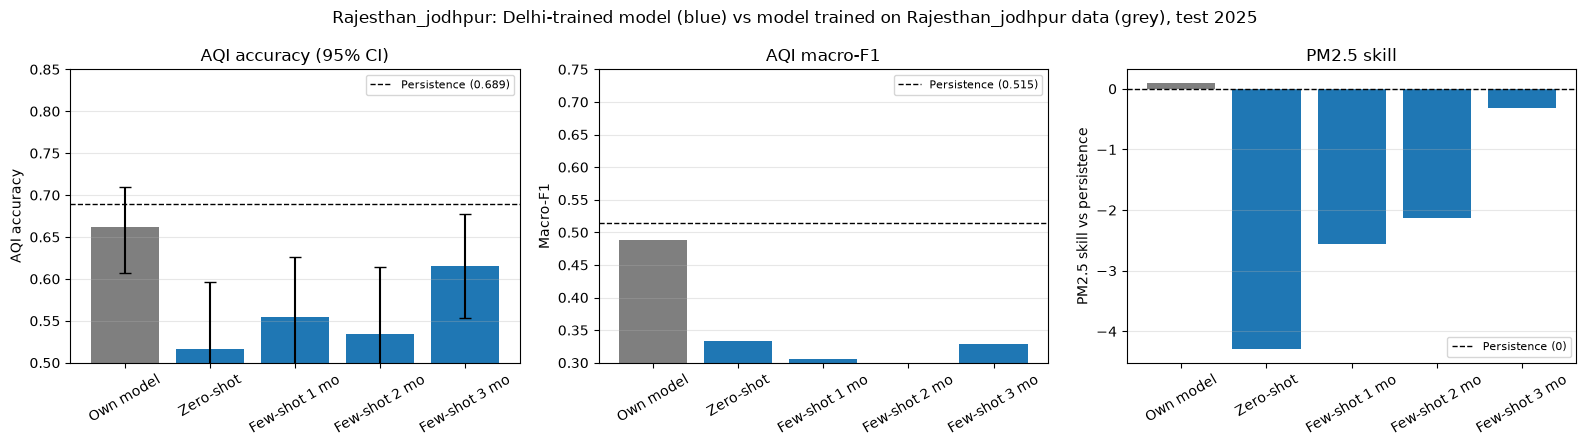

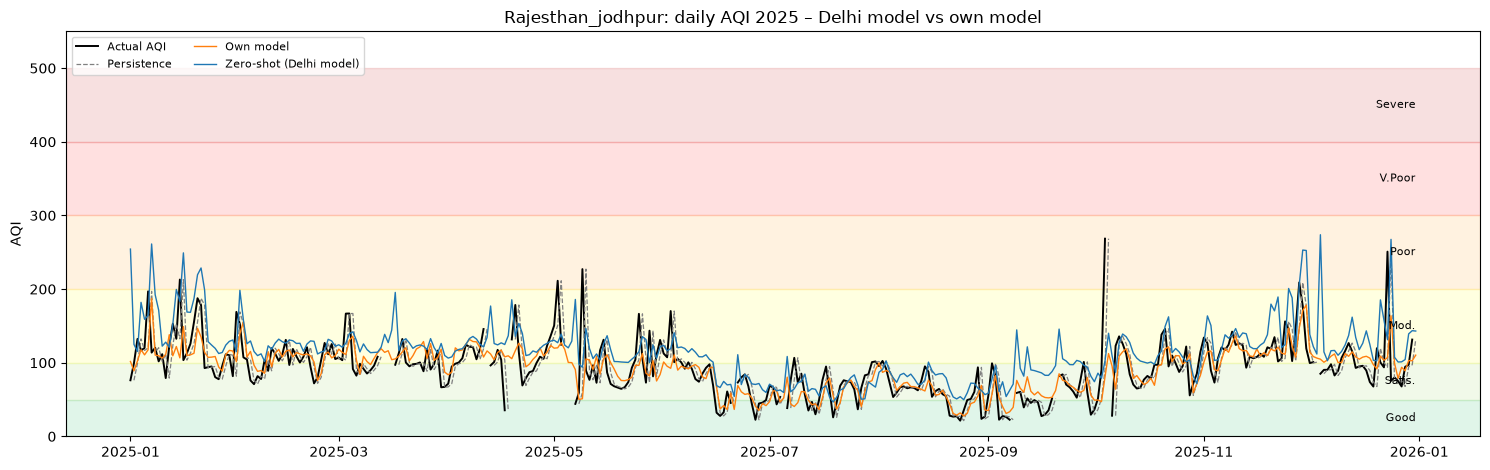

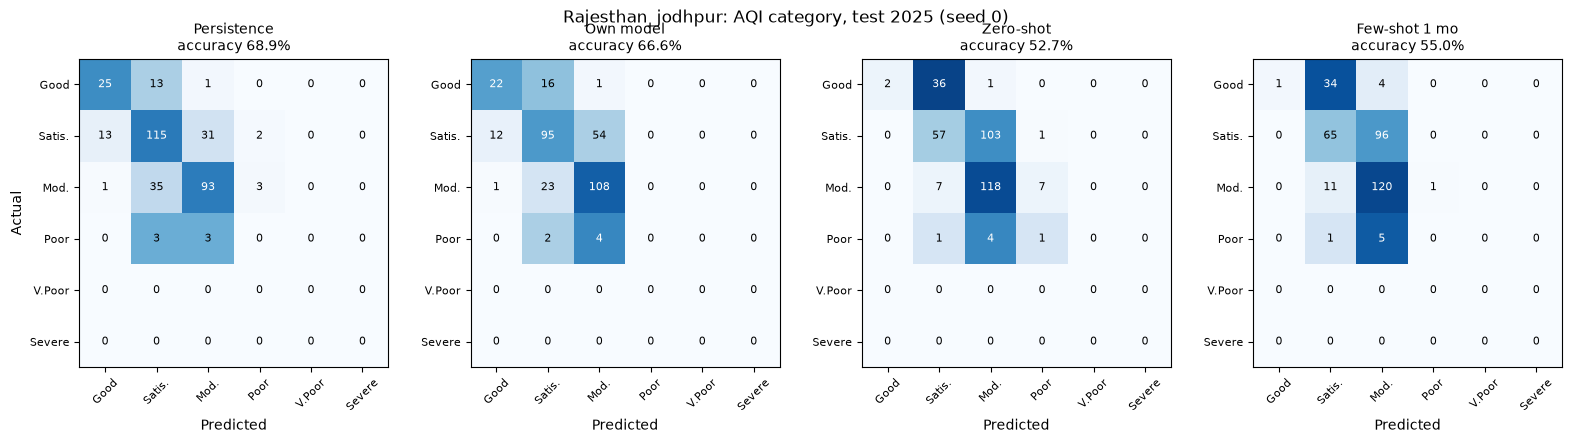

In [18]:
# ===== ITO – Part G plots: transferred model vs own model =====
from sklearn.metrics import confusion_matrix

SHORT   = ["Good", "Satis.", "Mod.", "Poor", "V.Poor", "Severe"]
BANDS   = [0, 50, 100, 200, 300, 400, 500]
COLOURS = ["#00b050", "#92d050", "#ffff00", "#ff9900", "#ff0000", "#c00000"]

def plot_transfer(station, setups, table, Y, pers, pols, test, fig_dir, own_key, zero_key):
    names = list(setups.keys())
    short = ["Own model" if n == own_key else n.replace("Few-shot: Delhi + ", "Few-shot ").replace(" of ITO", "")
             .replace(" month(s)", " mo").replace("Zero-shot (Delhi only)", "Zero-shot") for n in names]
    t = table.set_index("setup")
    pers_acc, pers_f1 = t.loc["Persistence", "accuracy"], t.loc["Persistence", "macro_F1"]
    bar_col = ["#7f7f7f" if n == own_key else "#1f77b4" for n in names]

    # ---- 1. scores by setup ----
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    acc = [t.loc[n, "accuracy"] for n in names]
    ci  = [tuple(map(float, t.loc[n, "acc_gain_95CI"].strip("[]").split(","))) for n in names]
    err = np.array([[a - (pers_acc + lo), (pers_acc + hi) - a] for a, (lo, hi) in zip(acc, ci)]).T
    axes[0].bar(short, acc, color=bar_col, yerr=err, capsize=4)
    axes[0].axhline(pers_acc, color="black", ls="--", lw=1, label=f"Persistence ({pers_acc:.3f})")
    axes[0].set_ylim(0.5, 0.85); axes[0].set_ylabel("AQI accuracy"); axes[0].set_title("AQI accuracy (95% CI)")
    axes[1].bar(short, [t.loc[n, "macro_F1"] for n in names], color=bar_col)
    axes[1].axhline(pers_f1, color="black", ls="--", lw=1, label=f"Persistence ({pers_f1:.3f})")
    axes[1].set_ylim(0.3, 0.75); axes[1].set_ylabel("Macro-F1"); axes[1].set_title("AQI macro-F1")
    axes[2].bar(short, [t.loc[n, "PM2.5_skill"] for n in names], color=bar_col)
    axes[2].axhline(0, color="black", ls="--", lw=1, label="Persistence (0)")
    axes[2].set_ylabel("PM2.5 skill vs persistence"); axes[2].set_title("PM2.5 skill")
    for ax in axes:
        ax.tick_params(axis="x", rotation=30); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
    plt.suptitle(f"{station}: Delhi-trained model (blue) vs model trained on {station} data (grey), test 2025")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_scores.png", dpi=300); plt.show()

    # ---- 2. AQI over 2025 ----
    a_true = U.compute_aqi(Y, pols)
    fig, ax = plt.subplots(figsize=(15, 4.8))
    d = Y.index[test]
    for lo, hi, c, lab in zip(BANDS[:-1], BANDS[1:], COLOURS, SHORT):
        ax.axhspan(lo, hi, color=c, alpha=0.12)
        ax.text(d[-1], (lo + hi) / 2, lab, fontsize=8, va="center", ha="right")
    ax.plot(a_true[test].asfreq("D"), color="black", lw=1.4, label="Actual AQI")
    ax.plot(U.compute_aqi(pers, pols)[test].asfreq("D"), color="grey", lw=0.9, ls="--", label="Persistence")
    ax.plot(U.compute_aqi(setups[own_key][0], pols)[test].asfreq("D"), color="tab:orange", lw=1, label="Own model")
    ax.plot(U.compute_aqi(setups[zero_key][0], pols)[test].asfreq("D"), color="tab:blue", lw=1, label="Zero-shot (Delhi model)")
    ax.set_ylim(0, 550); ax.set_ylabel("AQI"); ax.legend(fontsize=8, loc="upper left", ncol=2)
    ax.set_title(f"{station}: daily AQI 2025 – Delhi model vs own model")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_aqi_2025.png", dpi=300); plt.show()

    # ---- 3. confusion matrices ----
    show = {"Persistence": pers, "Own model": setups[own_key][0],
            "Zero-shot": setups[zero_key][0], "Few-shot 1 mo": setups[names[2]][0]}
    a_all = {k: U.compute_aqi(v, pols) for k, v in show.items()}
    ok = test & a_true.notna()
    for a in a_all.values():
        ok &= a.notna()
    code = {c: i for i, c in enumerate(U.CATS)}
    yt = U.to_cat(a_true[ok]).map(code).values
    fig, axes = plt.subplots(1, len(show), figsize=(4 * len(show), 4.2))
    for ax, (name, a) in zip(axes, a_all.items()):
        yp = U.to_cat(a[ok]).map(code).values
        cm = confusion_matrix(yt, yp, labels=range(6))
        pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
        for i in range(6):
            for j in range(6):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if pct[i, j] > 50 else "black")
        ax.set_title(f"{name}\naccuracy {(yt == yp).mean():.1%}", fontsize=10)
        ax.set_xticks(range(6)); ax.set_xticklabels(SHORT, rotation=45, fontsize=8)
        ax.set_yticks(range(6)); ax.set_yticklabels(SHORT, fontsize=8); ax.set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")
    plt.suptitle(f"{station}: AQI category, test 2025 (seed 0)")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/transfer_confusion.png", dpi=300); plt.show()

plot_transfer(STATION, setups, transfer_ito, Y, pers, POLS_T, test, FIG,
              own_key="Own ITO model (ITO 2023–24)", zero_key="Zero-shot (Delhi only)")

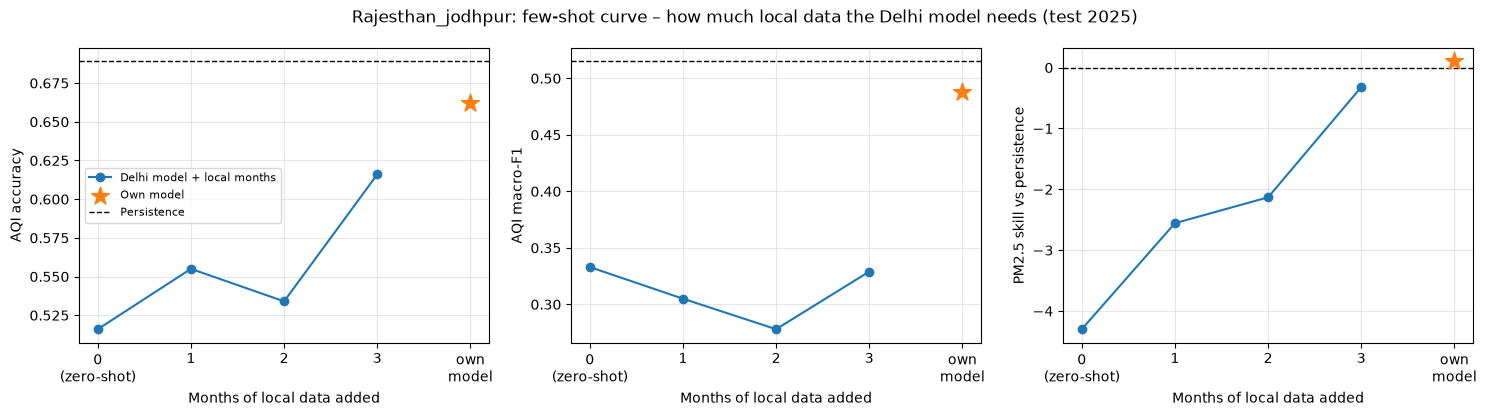

In [19]:
# ===== ITO – Part G plot: few-shot curve (0 -> 1 -> 2 -> 3 months of local data) =====
def plot_fewshot(station, table, zero_key, few_keys, own_key, fig_dir):
    t = table.set_index("setup")
    steps = [zero_key] + few_keys
    x = [0, 1, 2, 3]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (col, lab, base) in zip(axes, [("accuracy", "AQI accuracy", t.loc["Persistence", "accuracy"]),
                                           ("macro_F1", "AQI macro-F1", t.loc["Persistence", "macro_F1"]),
                                           ("PM2.5_skill", "PM2.5 skill vs persistence", 0)]):
        ax.plot(x, [t.loc[s, col] for s in steps], marker="o", color="tab:blue", label="Delhi model + local months")
        ax.scatter([4], [t.loc[own_key, col]], marker="*", s=180, color="tab:orange", zorder=5, label="Own model")
        ax.axhline(base, color="black", ls="--", lw=1, label="Persistence")
        ax.set_xticks([0, 1, 2, 3, 4]); ax.set_xticklabels(["0\n(zero-shot)", "1", "2", "3", "own\nmodel"])
        ax.set_xlabel("Months of local data added"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.suptitle(f"{station}: few-shot curve – how much local data the Delhi model needs (test 2025)")
    plt.tight_layout(); plt.savefig(f"{fig_dir}/fewshot_curve.png", dpi=300); plt.show()

plot_fewshot(STATION, transfer_ito,
             zero_key="Zero-shot (Delhi only)",
             few_keys=["Few-shot: Delhi + 1 month(s) of ITO",
                       "Few-shot: Delhi + 2 month(s) of ITO",
                       "Few-shot: Delhi + 3 month(s) of ITO"],
             own_key="Own ITO model (ITO 2023–24)",
             fig_dir=FIG)

In [20]:
pd.DataFrame({name: U.skill_per_pollutant(preds[0], test, Y, pers, POLS_T)
              for name, preds in setups.items()}).T

,PM2.5,PM10,NO2,SO2,NH3,CO
Own ITO model (ITO 2023–24),0.12,0.20,0.22,0.08,0.11,0.17
Zero-shot (Delhi only),-3.63,-0.15,-0.15,-1.79,0.01,-5.24
Few-shot: Delhi + 1 month(s) of ITO,-2.56,-0.11,-0.14,-1.64,-0.00,-3.06
Few-shot: Delhi + 2 month(s) of ITO,-1.86,-0.10,-0.10,-1.17,0.13,-3.80
Few-shot: Delhi + 3 month(s) of ITO,-0.26,0.15,-0.03,0.03,0.08,-1.33


In [21]:
# ===== ITO – Part G (second check): transfer scored on Jan–Sep 2026 =====
rows = [{"setup": "Persistence", **U.scores(pers, test2, Y, pers, POLS_T)}]
for name, preds in setups.items():
    sc = pd.DataFrame([U.scores(p, test2, Y, pers, POLS_T) for p in preds])
    ci = U.gain_ci(preds, test2, Y, pers, POLS_T)
    rows.append({"setup": name, "days": sc.days.iloc[0],
                 "accuracy": round(sc.accuracy.mean(), 3), "macro_F1": round(sc.macro_F1.mean(), 3),
                 "PM2.5_skill": round(sc["PM2.5_skill"].mean(), 3), "PM10_skill": round(sc["PM10_skill"].mean(), 3),
                 "acc_gain_95CI": ci["acc_gain_95CI"], "F1_gain_95CI": ci["F1_gain_95CI"]})
transfer_ito_2026 = pd.DataFrame(rows)
print(f"Transfer Delhi -> {STATION}, test Jan–Sep 2026 (models trained up to Dec 2024):")
print(transfer_ito_2026.to_string(index=False))

# same check at R K Puram for 2026 (5 shared pollutants)
d_test2 = U.in_period(Xd.index, "test2")
sc = pd.DataFrame([U.scores(p, d_test2, Yd, pers_d, POLS_T) for p in d5])
ci = U.gain_ci(d5, d_test2, Yd, pers_d, POLS_T)
print(f"\nCheck – R K Puram Jan–Sep 2026, 5 shared pollutants: persistence acc "
      f"{U.scores(pers_d, d_test2, Yd, pers_d, POLS_T)['accuracy']} | model acc {sc.accuracy.mean():.3f} | "
      f"acc gain {ci['acc_gain']:+.3f} {ci['acc_gain_95CI']} | PM2.5 skill {sc['PM2.5_skill'].mean():.3f}")

Transfer Delhi -> Rajesthan_jodhpur, test Jan–Sep 2026 (models trained up to Dec 2024):
                              setup  days  accuracy  macro_F1  PM2.5_skill  PM10_skill    acc_gain_95CI     F1_gain_95CI
                        Persistence   260     0.681     0.368        0.000       0.000              NaN              NaN
        Own ITO model (ITO 2023–24)   260     0.705     0.357        0.208       0.006 [-0.037, +0.075] [-0.087, +0.154]
             Zero-shot (Delhi only)   260     0.480     0.242       -6.405      -0.790 [-0.324, -0.088] [-0.394, -0.045]
Few-shot: Delhi + 1 month(s) of ITO   260     0.470     0.297       -4.618      -0.847 [-0.338, -0.103] [-0.352, +0.070]
Few-shot: Delhi + 2 month(s) of ITO   260     0.458     0.291       -4.158      -0.785 [-0.353, -0.115] [-0.362, +0.062]
Few-shot: Delhi + 3 month(s) of ITO   260     0.630     0.341       -0.249      -0.180 [-0.148, +0.028] [-0.239, +0.104]

Check – R K Puram Jan–Sep 2026, 5 shared pollutants: persistence

In [22]:
# ===== ITO – why does the Delhi model work as well as ITO's own? =====
# 1. how similar are R K Puram and ITO, day by day (2023–2025)?
common_days = Y.index.intersection(Yd.index)
common_days = common_days[(common_days >= "2023-01-01") & (common_days <= "2025-12-31")]
print("Day-to-day correlation, R K Puram vs ITO:")
for p in POLS_T:
    print(f"  {p}: {Yd.loc[common_days, p].corr(Y.loc[common_days, p]):.2f}")

# 2. zero-shot vs own ITO model, directly (own model used as the baseline)
own0 = setups["Own ITO model (ITO 2023–24)"][0]
for label, days in [("2025", test), ("Jan–Sep 2026", test2)]:
    c = U.gain_ci(setups["Zero-shot (Delhi only)"], days, Y, own0, POLS_T)
    print(f"\nZero-shot minus own ITO model, {label}: accuracy {c['acc_gain']:+.3f} {c['acc_gain_95CI']} | "
          f"macro-F1 {c['F1_gain']:+.3f} {c['F1_gain_95CI']}")

Day-to-day correlation, R K Puram vs ITO:
  PM2.5: 0.71
  PM10: 0.49
  NO2: 0.39
  SO2: 0.26
  NH3: 0.28
  CO: 0.48

Zero-shot minus own ITO model, 2025: accuracy -0.153 [-0.218, -0.078] | macro-F1 -0.182 [-0.230, -0.085]

Zero-shot minus own ITO model, Jan–Sep 2026: accuracy -0.211 [-0.315, -0.107] | macro-F1 -0.112 [-0.356, -0.065]


### At Jodhpur (Mandor, a desert station about 480 km from Delhi), all six AQI pollutants passed the sensor checks. The leakage result repeated (97.0% vs 100% for the formula). A model trained on Jodhpur’s own data did not beat persistence on AQI category (66.2% vs 68.9%), although it improved PM forecasts (PM2.5 skill +0.10, PM10 +0.20). Without local data, the Delhi model failed for PM2.5 (skill −4.30) but stayed close to persistence for PM10 (−0.14), consistent with Jodhpur’s dust-driven PM10 being closer to Delhi’s levels than its PM2.5. With 3 months of local data, PM10 skill reached +0.14, near the local model, while PM2.5 skill improved to −0.32.

In [23]:
# ===== Part I: SHAP top inputs of this station's own model (for the summary table) =====
import shap
rows = []
for p in ["PM2.5", "PM10"]:
    ok = fit & Y[p].notna()
    ttr = U.build_pipeline("ExtraTrees", {**FINAL_PARAMS["ExtraTrees"], "random_state": 0}).fit(X[ok], Y.loc[ok, p])
    pipe = ttr.regressor_
    Xt = X[test & Y[p].notna()]
    Xf = pd.DataFrame(pipe["fill"].transform(Xt), index=Xt.index, columns=X.columns)
    sv = shap.TreeExplainer(pipe["model"]).shap_values(Xf, check_additivity=False)
    share = pd.Series(np.abs(sv).mean(axis=0), index=X.columns)
    share = (share / share.sum() * 100).sort_values(ascending=False).head(8).round(1)
    print(f"\n{STATION} – {p}: top 8 inputs (% of mean |SHAP|)"); print(share)
    rows += [{"station": STATION, "target": p, "rank": i + 1, "input": k, "share_%": v}
             for i, (k, v) in enumerate(share.items())]
pd.DataFrame(rows).to_csv(f"{SUMMARY_DIR}/shap_{STATION}.csv", index=False)


Rajesthan_jodhpur – PM2.5: top 8 inputs (% of mean |SHAP|)
doy_cos             25.8
PM2.5_lag1          16.4
PM2.5_mean7          8.7
PM10_lag1            5.5
surface_pressure     5.1
PM2.5_lag2           4.0
SO2_mean7            3.9
SO2_lag3             2.4
dtype: float64

Rajesthan_jodhpur – PM10: top 8 inputs (% of mean |SHAP|)
PM10_lag1      30.6
PM10_mean7     10.7
PM10_lag2       6.3
SO2_mean7       5.7
cloud_cover     4.8
RF              3.5
PM10_lag3       3.4
PM2.5_lag1      3.0
dtype: float64


In [24]:
a = aqi_true[test].dropna()
print(f"Days within ±15 of AQI 100: {((a - 100).abs() <= 15).mean():.0%} of 2025")

Days within ±15 of AQI 100: 37% of 2025


At Jodhpur, the model improved PM forecasts over persistence (PM2.5 skill +0.10, PM10 +0.20), but not AQI-category accuracy, since 37% of days lay within 15 points of the AQI-100 boundary. PM10 forecasts relied mainly on the previous days’ PM10 (51% of SHAP importance), as at Delhi, which is consistent with PM10 transferring almost without loss (zero-shot skill −0.14). PM2.5 relied mainly on season (26%), and its lower seasonal level than Delhi’s is consistent with the failed PM2.5 transfer (−4.30).

In [25]:
Y.to_csv(f"{SUMMARY_DIR}/daily_{STATION}.csv")
transfer_table.to_csv(f"{SUMMARY_DIR}/transfer_{STATION}.csv", index=False)

In [26]:
X.to_csv(f"{SUMMARY_DIR}/X_{STATION}.csv")

In [27]:
# valid daily values (%) after QC: day counts if >= 16 valid hours
SEVEN = ["PM2.5", "PM10", "NO2", "SO2", "NH3", "CO", "OZONE"]
have = [p for p in SEVEN if p in data.columns]
print("not in data:", [p for p in SEVEN if p not in have])

days = pd.date_range("2023-01-01", "2026-09-30", freq="D")
valid_hours = data[have].notna().resample("D").sum().reindex(days, fill_value=0)
print(((valid_hours >= 16).mean() * 100).round(1))

not in data: ['OZONE']
PM2.5    88.8
PM10     89.0
NO2      89.6
SO2      89.3
NH3      89.2
CO       88.7
dtype: float64
